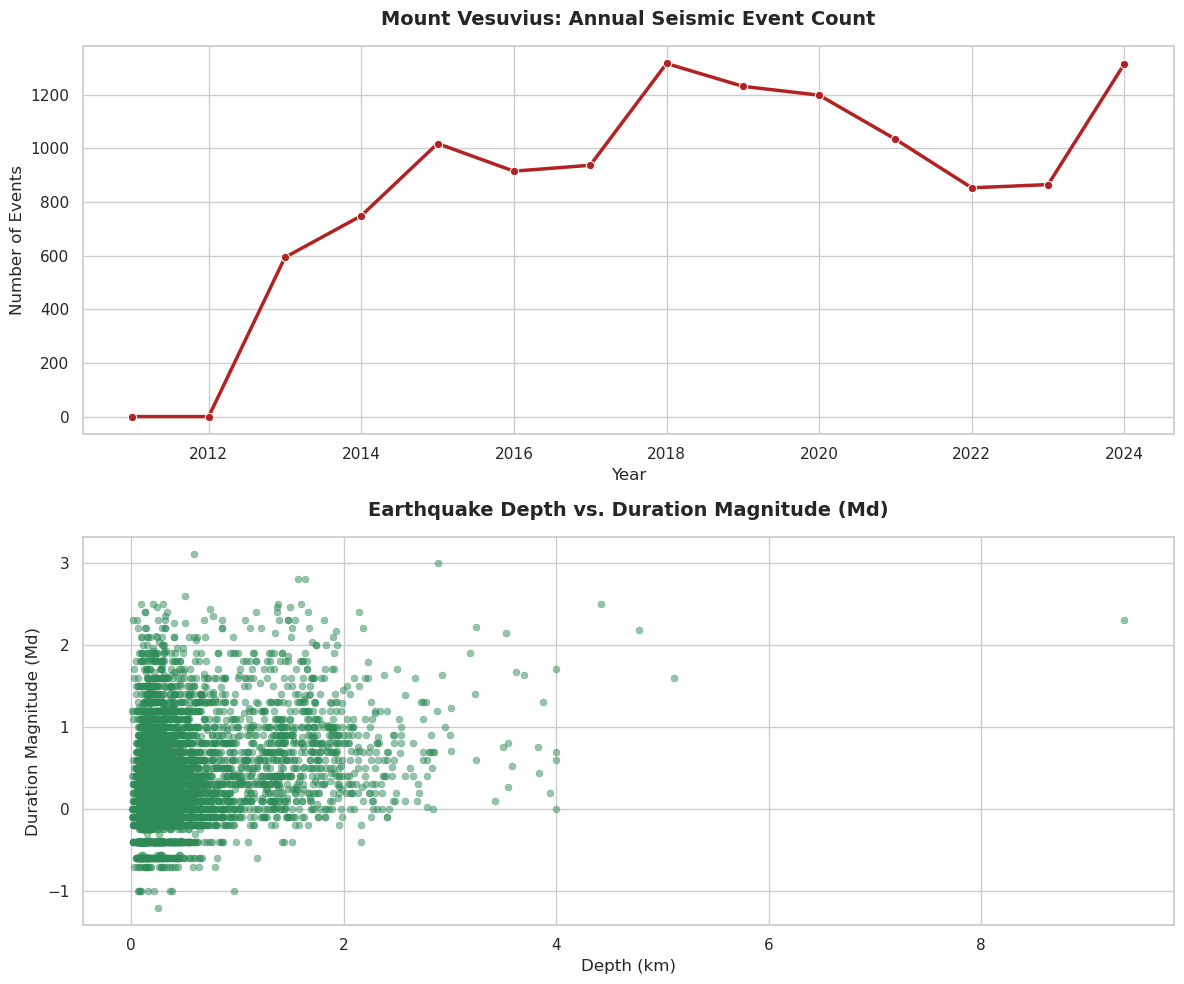

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from GitHub
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-05-13/vesuvius.csv'
df = pd.read_csv(url)

# Ensure 'time' is parsed as datetime and extract year if not already present
df['time'] = pd.to_datetime(df['time'])
if 'year' not in df.columns:
  df['year'] = df['time'].dt.year

# Set up the plotting style
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

# --- Panel 1: Number of Seismic Events Per Year ---
events_per_year = df.groupby('year').size().reset_index(name='event_count')

sns.lineplot(
    data=events_per_year,
    x='year',
    y='event_count',
    ax=axes[0],
    marker='o',
    color='#b22222',
    linewidth=2.5,
)
axes[0].set_title(
    'Mount Vesuvius: Annual Seismic Event Count',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
axes[0].set_xlabel('Year', fontsize=12)
axes[0].set_ylabel('Number of Events', fontsize=12)

# --- Panel 2: Depth vs. Duration Magnitude ---
# Filter out extreme outliers or missing values if any
clean_df = df.dropna(subset=['depth_km', 'duration_magnitude_md'])

sns.scatterplot(
    data=clean_df,
    x='depth_km',
    y='duration_magnitude_md',
    ax=axes[1],
    alpha=0.5,
    color='#2e8b57',
    edgecolor=None,
    s=25,
)
axes[1].set_title(
    'Earthquake Depth vs. Duration Magnitude (Md)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
axes[1].set_xlabel('Depth (km)', fontsize=12)
axes[1].set_ylabel('Duration Magnitude (Md)', fontsize=12)

# Adjust layout and display the plot
plt.tight_layout()
plt.savefig('vesuvius_seismic_analysis.png', dpi=300)
plt.show()